# Step 4 – Preprocessing
**Project:** Paper Leak Sentiment Analysis Using Federated Learning

Goal: turn raw comments into clean text and then into numbers (features) a model can learn from.

| Stage | What happens |
|---|---|
| 1. Cleaning | lowercase, remove links/mentions, emojis → words, slang → standard words, numbers → `num` |
| 2. Tokenization | split on spaces – works for English, Hinglish **and Hindi (Devanagari)** |
| 3. Stop words | remove filler words but **keep negations** (not, no, nahi) |
| 4. Split | train 80% / validation 10% / test 10%, balanced, no text shared between splits |
| 5. Features | **TF-IDF** for centralized models, **Hashing** for federated learning |

The code lives in `src/preprocess.py`; running `python src/preprocess.py` creates `train.csv`, `val.csv`, `test.csv` and `models/tfidf_vectorizer.joblib`.

In [1]:
import re, sys
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from preprocess import clean_text, make_hashing, STOPWORDS, NEGATIONS

FIG = ROOT / "results" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
raw   = pd.read_csv(ROOT / "data/processed/paper_leak_comments.csv")
train = pd.read_csv(ROOT / "data/processed/train.csv")
val   = pd.read_csv(ROOT / "data/processed/val.csv")
test  = pd.read_csv(ROOT / "data/processed/test.csv")
print(f"raw {len(raw):,} | train {len(train):,} | val {len(val):,} | test {len(test):,}")

raw 100,002 | train 80,002 | val 10,000 | test 10,000


In [2]:
from matplotlib import font_manager
FONT = "Segoe UI" if any(f.name == "Segoe UI" for f in font_manager.fontManager.ttflist) else "DejaVu Sans"
SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
SENT = {"negative": "#e34948", "neutral": "#898781", "positive": "#2a78d6"}; ORDER = list(SENT)
plt.rcParams.update({"font.family": FONT, "font.size": 10, "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE, "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelcolor": INK2, "ytick.labelcolor": INK2, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True, "legend.frameon": False,
    "savefig.dpi": 200, "savefig.bbox": "tight"})
def title(ax, main, sub=None):
    ax.set_title(main, loc="left", fontsize=13, fontweight="bold", color=INK, pad=24 if sub else 10)
    if sub: ax.text(0, 1.02, sub, transform=ax.transAxes, fontsize=9.5, color=INK2, va="bottom")

## 1. Cleaning – before and after

In [3]:
examples = [
    "Great job NTA, another leak 👏👏 #NEETScam https://t.co/xyz @NTA_Exams",
    "u r right, ppl r soooo angry!!! 😡",
    "I don't trust the CBI on this. 23 people arrested but nothing will change...",
    "bhai paper phir se leak 😩 padhai karne ka kya fayda??",
    "हिम्मत रखो, दोबारा मेहनत करेंगे और सफल होंगे 💪",
    "When is the retest date? Is the old admit card valid?",
]
pd.set_option("display.max_colwidth", 120)
pd.DataFrame({"original": examples, "cleaned": [clean_text(e) for e in examples]})

,original,cleaned
0,"Great job NTA, another leak 👏👏 #NEETScam https://t.co/xyz @NTA_Exams",great job nta another leak emo_clap emo_clap neetscam
1,"u r right, ppl r soooo angry!!! 😡",you right people soo angry exclaim emo_angry
2,I don't trust the CBI on this. 23 people arrested but nothing will change...,i do not trust cbi num people arrested but nothing will change ellipsis
3,bhai paper phir se leak 😩 padhai karne ka kya fayda??,bhai paper phir leak emo_sad padhai karne kya fayda qmark
4,"हिम्मत रखो, दोबारा मेहनत करेंगे और सफल होंगे 💪",हिम्मत रखो दोबारा मेहनत करेंगे और सफल होंगे emo_strong
5,When is the retest date? Is the old admit card valid?,when retest date qmark old admit card valid qmark


What changed:
- Links and @mentions are removed; the hashtag **word** is kept (`#NEETScam` → `neetscam`), because hashtags often carry sentiment.
- **Emojis become words** (`😡` → `emo_angry`, `💪` → `emo_strong`). Emojis are strong sentiment signals, so deleting them would throw information away.
- **`!` and `?` become tokens** (`exclaim`, `qmark`). Questions are a strong hint for *neutral*, exclamations for strong feelings.
- **Slang is normalised** (`u` → `you`, `ppl` → `people`, `don't`/`dont` → `do not`), so variants count as the same word.
- Stretched letters are shortened (`soooo` → `soo`), and numbers become `num`, since the exact number of arrests does not change the sentiment.

## 2. Two common mistakes we avoided
### (a) The default tokenizer breaks Hindi words
Python's `\w` does not treat Devanagari vowel signs (matras) as letters, so the usual tokenizer chops Hindi words into pieces.

In [4]:
w = "हिम्मत रखो"
print("default \\w+ tokenizer :", re.findall(r"\w+", w))
print("our tokenizer (spaces):", clean_text(w).split())

default \w+ tokenizer : ['ह', 'म', 'मत', 'रख']
our tokenizer (spaces): ['हिम्मत', 'रखो']


### (b) Standard stop-word lists delete negations
scikit-learn's English stop-word list contains *not, no, never, nothing*. Removing them flips the meaning:

In [5]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
s = "i do not trust the cbi"
print("sklearn stop words :", " ".join(w for w in s.split() if w not in ENGLISH_STOP_WORDS))
print("our stop words     :", clean_text(s))
print("\nnegations we always keep:", sorted(NEGATIONS))
print(f"our stop-word list has only {len(STOPWORDS)} words (English + Hinglish fillers)")

sklearn stop words : trust cbi
our stop words     : i do not trust cbi

negations we always keep: ['mat', 'na', 'nahi', 'never', 'no', 'nobody', 'none', 'nor', 'not', 'nothing']
our stop-word list has only 40 words (English + Hinglish fillers)


## 3. Effect on the whole dataset

Average tokens per comment: 12.2 before -> 10.4 after cleaning
Empty comments after cleaning: 0


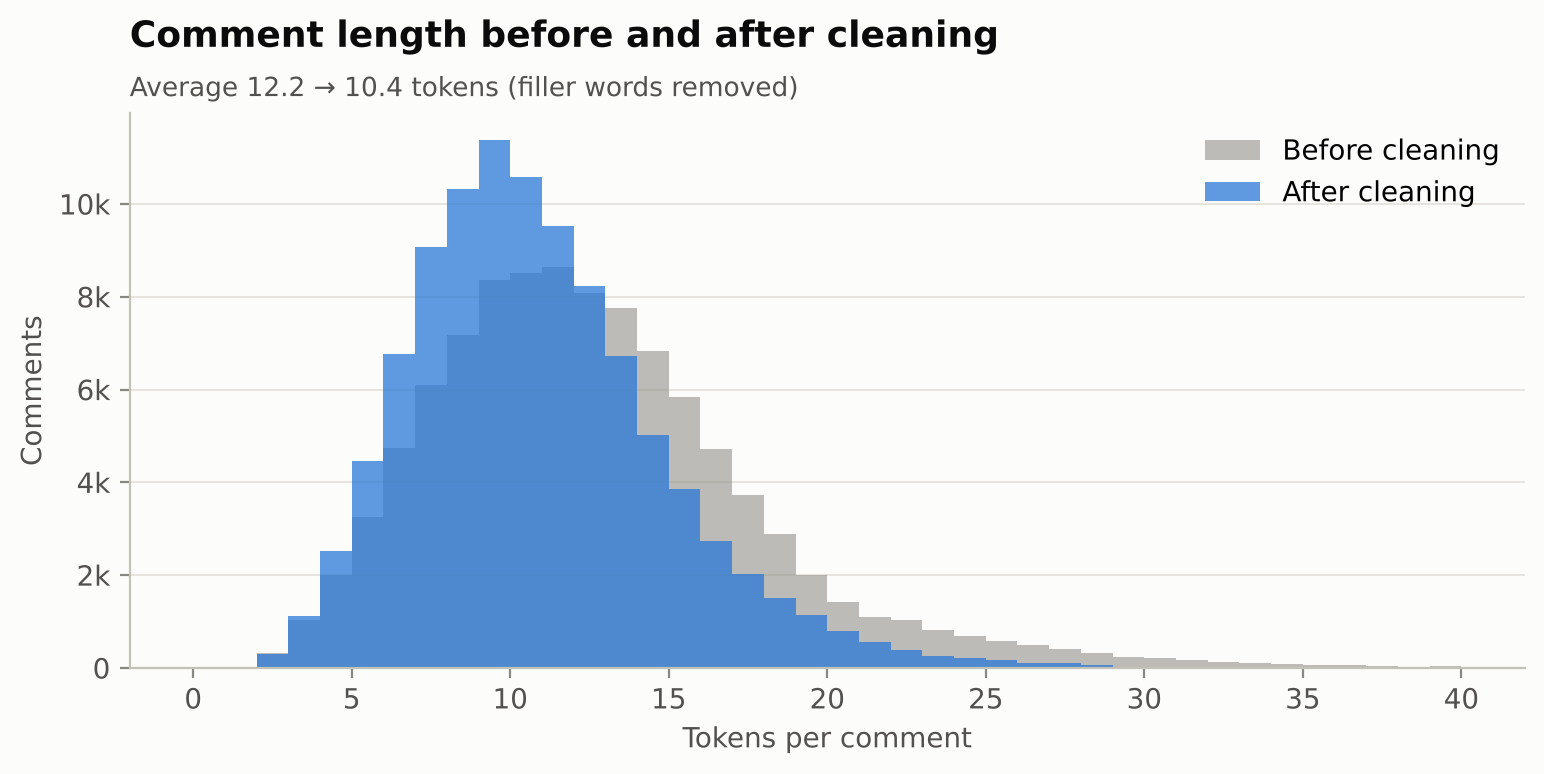

In [6]:
allc = pd.concat([train, val, test], ignore_index=True)
before = allc.text.str.split().str.len()
after  = allc.clean_text.str.split().str.len()
print(f"Average tokens per comment: {before.mean():.1f} before -> {after.mean():.1f} after cleaning")
print(f"Empty comments after cleaning: {(after == 0).sum()}")

fig, ax = plt.subplots(figsize=(9, 3.6))
bins = np.arange(0, 41, 1)
ax.hist(before, bins=bins, color=MUTED, alpha=0.55, label="Before cleaning")
ax.hist(after, bins=bins, color=SENT["positive"], alpha=0.75, label="After cleaning")
ax.grid(axis="x", visible=False); ax.set_xlabel("Tokens per comment"); ax.set_ylabel("Comments")
ax.yaxis.set_major_formatter(lambda x, _: f"{x/1000:g}k" if x >= 1000 else f"{x:g}")
ax.legend(loc="upper right")
title(ax, "Comment length before and after cleaning", f"Average {before.mean():.1f} → {after.mean():.1f} tokens (filler words removed)")
fig.savefig(FIG / "C1_tokens_before_after.png"); plt.show()

## 4. Train / validation / test split
- **80 / 10 / 10**, stratified so every split has the same label balance.
- **Grouped by cleaned text**: if two comments become identical after cleaning, they go to the same split. Otherwise the model would be tested on sentences it already saw in training, and the scores would look better than they really are.
- **Same split for every model** (centralized, local and federated), so the comparison in Step 8 is fair.

In [7]:
splits = pd.concat([train.assign(split="train"), val.assign(split="val"), test.assign(split="test")], ignore_index=True)
tab = pd.crosstab(splits.split, splits.label).reindex(["train", "val", "test"])
tab["total"] = tab.sum(axis=1); tab["share"] = (tab.total / tab.total.sum()).map("{:.0%}".format)
display(tab)
display(pd.crosstab(splits.split, splits.platform).reindex(["train", "val", "test"]))
print("Cleaned texts appearing in both train and test:", len(set(train.clean_text) & set(test.clean_text)))

label,negative,neutral,positive,total,share
split,,,,,
train,26668,26667,26667,80002,80%
val,3333,3334,3333,10000,10%
test,3333,3333,3334,10000,10%


platform,Instagram,NewsPortal,Reddit,X,YouTube
split,,,,,
train,15465,12692,13347,20846,17652
val,1943,1626,1670,2530,2231
test,1980,1608,1648,2691,2073


Cleaned texts appearing in both train and test: 0


## 5. Features
### TF-IDF (for centralized models, Step 5)
Each comment becomes a vector of word and word-pair (bigram) weights. Bigrams matter here: *"not fair"* and *"trust"* vs *"don't trust"*.
The vectorizer is **fitted on the training set only**.

In [8]:
tfidf = joblib.load(ROOT / "models/tfidf_vectorizer.joblib")
Xtr = tfidf.transform(train.clean_text)
print(f"TF-IDF matrix (train): {Xtr.shape[0]:,} comments x {Xtr.shape[1]:,} features")
print(f"Sparsity: {1 - Xtr.nnz / (Xtr.shape[0] * Xtr.shape[1]):.4%} of values are zero")
bigrams = [t for t in tfidf.vocabulary_ if " " in t]
print(f"Unigrams: {len(tfidf.vocabulary_) - len(bigrams):,}   Bigrams: {len(bigrams):,}")

TF-IDF matrix (train): 80,002 comments x 31,708 features
Sparsity: 99.9395% of values are zero
Unigrams: 3,625   Bigrams: 28,083


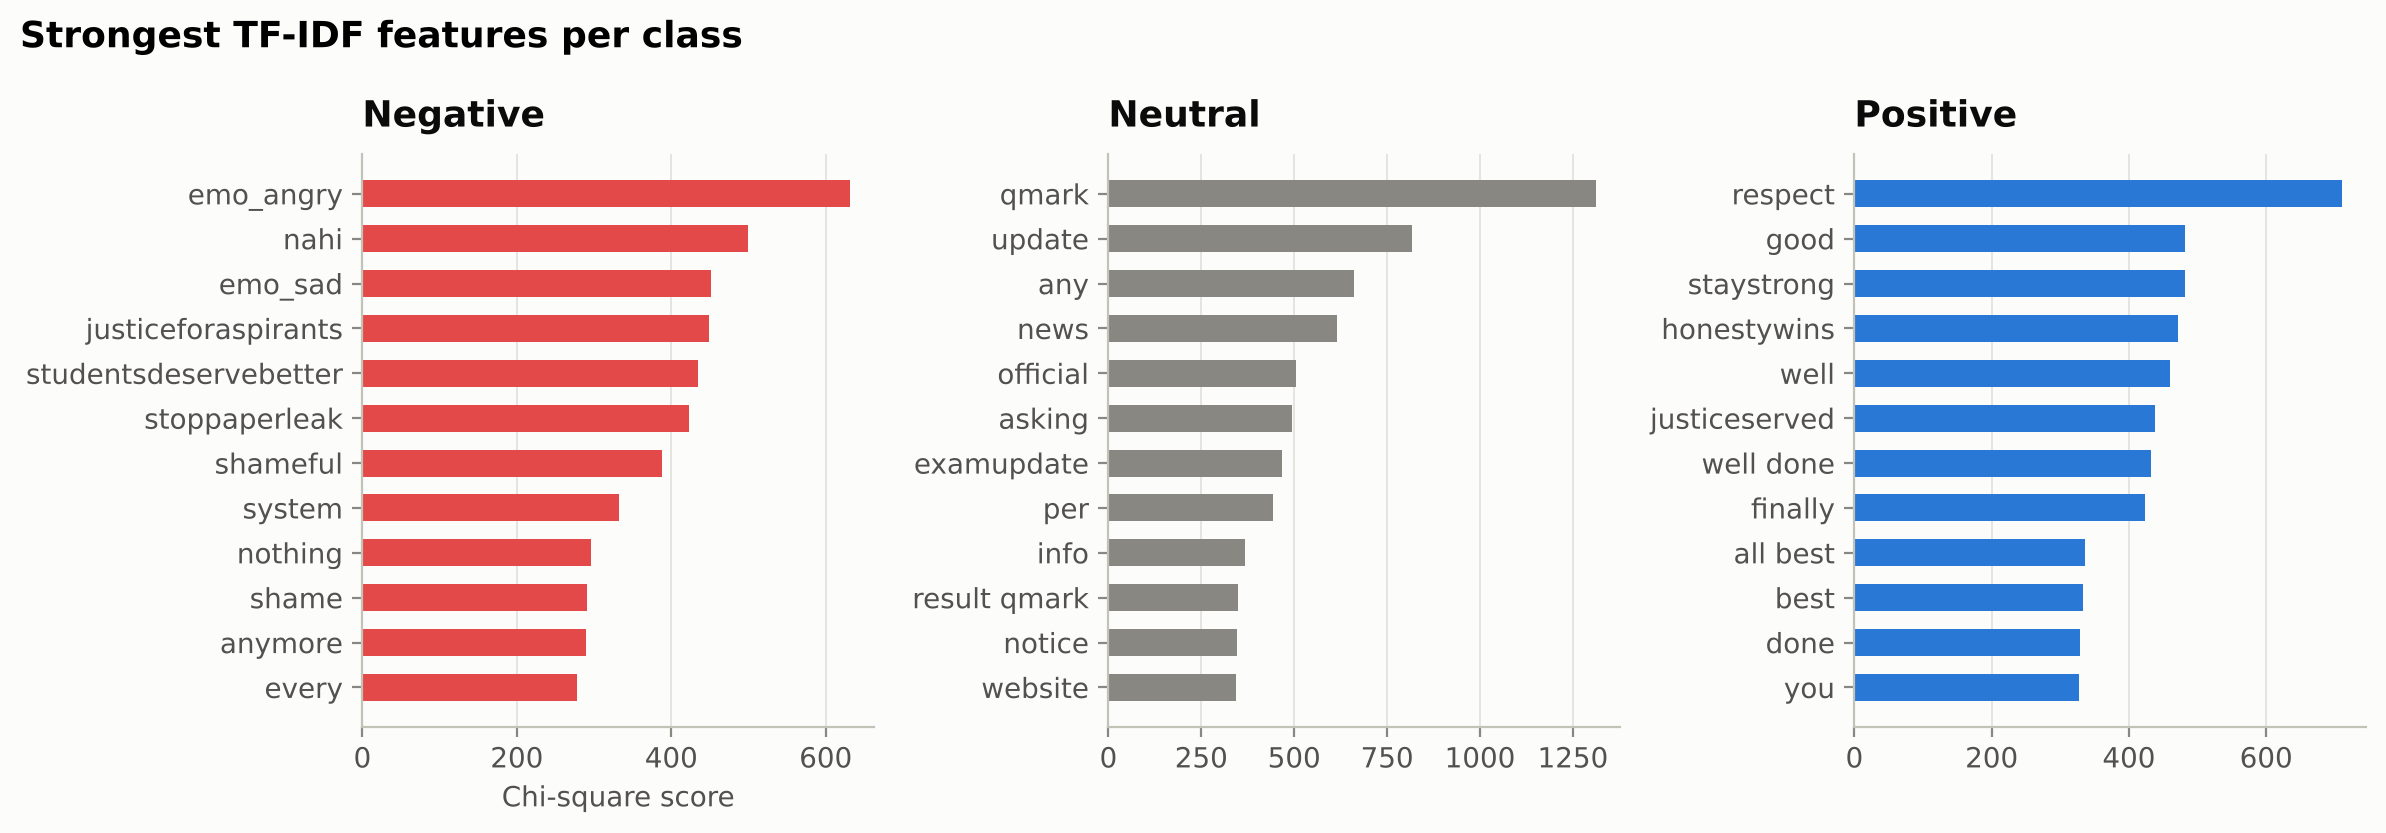

In [9]:
from sklearn.feature_selection import chi2
from sklearn.preprocessing import LabelBinarizer
names = np.array(tfidf.get_feature_names_out())
Y = LabelBinarizer().fit(ORDER).transform(train.label)
fig, axes = plt.subplots(1, 3, figsize=(12, 4.2))
for j, (ax, c) in enumerate(zip(axes, ORDER)):
    scores, _ = chi2(Xtr, Y[:, j])
    mean_in = np.asarray(Xtr[Y[:, j] == 1].mean(axis=0)).ravel()
    mean_out = np.asarray(Xtr[Y[:, j] == 0].mean(axis=0)).ravel()
    scores = np.where(mean_in > mean_out, scores, 0)          # only features that point TO this class
    top = np.argsort(scores)[::-1][:12][::-1]
    ax.barh(names[top], scores[top], color=SENT[c], height=0.6)
    ax.grid(axis="y", visible=False); ax.xaxis.set_major_formatter(lambda x, _: f"{x:g}")
    title(ax, c.capitalize())
axes[0].set_xlabel("Chi-square score")
fig.suptitle("Strongest TF-IDF features per class", x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout(); fig.savefig(FIG / "C2_top_tfidf_features.png"); plt.show()

`qmark` (a question mark) is the strongest *neutral* signal, `emo_angry` the strongest *negative* one, and bigrams such as *"well done"* and *"result qmark"* make the top lists. This shows why converting emojis and punctuation into words, and using bigrams, was worth it.

### Hashing features (for federated learning, Step 7)
TF-IDF needs one shared **vocabulary**, built by looking at everyone's text. In federated learning the server is not allowed to see client text, so that would break privacy.

The **Hashing vectorizer** solves this: each word is mapped to a column by a fixed hash function. Every client produces vectors in the same 262,144-dimensional space on its own, with no vocabulary and no text ever shared.

In [10]:
hv = make_hashing()
Xh = hv.transform(train.clean_text.head(3))
print("Hashing features per comment:", Xh.shape[1])
print("Needs fitting on shared data? ", hasattr(hv, "vocabulary_"), "-> no vocabulary, nothing to share")
client_a = hv.transform(["paper leak again emo_angry"])     # computed on client A
client_b = hv.transform(["paper leak again emo_angry"])     # computed independently on client B
print("Client A and B produce identical columns:", (client_a != client_b).nnz == 0)

Hashing features per comment: 262144
Needs fitting on shared data?  False -> no vocabulary, nothing to share
Client A and B produce identical columns: True


## Summary

In [11]:
summary = pd.DataFrame({"item": [
    "Comments after cleaning", "Train / Val / Test", "Texts shared between train and test",
    "TF-IDF features (1–2 grams, fitted on train)", "Hashing features (for FL)", "Languages handled"],
  "value": [f"{len(allc):,} (none became empty)" if (after == 0).sum() == 0 else f"{len(allc):,}",
            f"{len(train):,} / {len(val):,} / {len(test):,} (each balanced across the 3 classes)",
            len(set(train.clean_text) & set(test.clean_text)), f"{len(tfidf.vocabulary_):,}", f"{2**18:,}",
            "English, Hinglish, Hindi (Devanagari), Telugu-English"]})
summary.style.hide(axis="index")

item,value
Comments after cleaning,"100,002 (none became empty)"
Train / Val / Test,"80,002 / 10,000 / 10,000 (each balanced across the 3 classes)"
Texts shared between train and test,0
"TF-IDF features (1–2 grams, fitted on train)","31,708"
Hashing features (for FL),"262,144"
Languages handled,"English, Hinglish, Hindi (Devanagari), Telugu-English"


**Next:** Step 5 – train centralized baseline models (Naive Bayes, Logistic Regression, Linear SVM) on these features.